In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision.utils as vutils
import sklearn
from pycocotools.coco import COCO
from skimage.color import rgb2gray
from skimage.filters import sobel
from scipy.fft import fft2, fftshift
from scipy.stats import skew, kurtosis
from PIL import Image
import cv2

from compcats.datasets.fmri import nsd
from compcats.utils import model_utils, responsecomparison_utils as rc_utils
from compcats.datasets.fmri.utils import nsd_ds_utils

import main_analysis as ma
import paths

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ImportWarning)
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)
warnings.filterwarnings("ignore", category=Warning)  # catch-all for any base warnings
warnings.filterwarnings("ignore")

coco_train_annotations = COCO(paths.COCO_TRAIN_ANNOTATIONS_PATH)
coco_train_captions = COCO(paths.COCO_TRAIN_CAPTIONS_PATH)
coco_val_annotations = COCO(paths.COCO_VAL_ANNOTATIONS_PATH)
coco_val_captions = COCO(paths.COCO_VAL_CAPTIONS_PATH)

RESULTS_DIR = 'results/exploration/break_ems'
os.makedirs(RESULTS_DIR, exist_ok=True)
PLOTS_DIR = 'results/exploration/break_ems/plots'
os.makedirs(PLOTS_DIR, exist_ok=True)

loading annotations into memory...
Done (t=7.12s)
creating index...
index created!
loading annotations into memory...
Done (t=0.52s)
creating index...
index created!
loading annotations into memory...
Done (t=0.30s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


In [2]:
# Utils

def _get_mapping_object(mapper, alpha, seed):
    if mapper == 'l1pos':
        # Use L1 positive mapping
        mapping = sklearn.linear_model.Lasso(
            alpha=alpha, positive=True, random_state=seed
        )
    elif mapper == 'ridge':
        # Use Ridge regression mapping
        mapping = sklearn.linear_model.Ridge(alpha=alpha, random_state=seed)
    return mapping

# Get end to end torch encoding model
class EM(torch.nn.Module):
    def __init__(self, model, layer, mapping_coef, mapping_intercept):
        super(EM, self).__init__()
        self.model = model
        self.layer = layer
        
        # Convert sklearn mapping to torch.nn.Linear
        n_features = mapping_coef.shape[1]
        n_outputs = mapping_coef.shape[0]
        self.mapping_layer = torch.nn.Linear(n_features, n_outputs)
        
        # Set weights and bias from the sklearn model
        self.mapping_layer.weight.data = torch.FloatTensor(mapping_coef)
        self.mapping_layer.bias.data = torch.FloatTensor(mapping_intercept)
        
        # Get the layer module
        self.layer_module = dict([*self.model.model.named_modules()])[self.layer]
        
        # Register a forward hook to get the activations
        self.activations = None
        def hook(module, input, output):
            self.activations = output
        self.layer_module.register_forward_hook(hook)
    
    def forward(self, x):
        _ = self.model(x)
        # Get the activations
        x = self.activations
        x = x.reshape(x.shape[0], -1)
        # Apply the mapping directly with torch Linear layer
        x_mapped = self.mapping_layer(x)
        return x_mapped

def get_image_labels(image_id, annotations_obj, captions_obj):
    """
    Get the labels for an image given its ID from the COCO dataset.
    
    Args:
        image_id (int): The ID of the image.
        
    Returns:
        list: A list of labels (category names) associated with the image.
    """
    # Get all annotations for the given image
    annotation_ids = annotations_obj.getAnnIds(imgIds=image_id)
    annotations = annotations_obj.loadAnns(annotation_ids)
    # Get category IDs from annotations
    category_ids = {annotation['category_id'] for annotation in annotations}
    # Get category names from category IDs
    category_names = [annotations_obj.loadCats(cat_id)[0]['name'] for cat_id in category_ids]

    # Get captions for the image
    caption_ids = captions_obj.getAnnIds(imgIds=image_id)
    captions = captions_obj.loadAnns(caption_ids)
    caption_texts = [caption['caption'] for caption in captions]
    
    return category_names, caption_texts

def add_image_info_to_df(df):
    """
    Add labels to the DataFrame given the COCO object.
    
    Args:
        df (pd.DataFrame): The DataFrame to which to add the labels.
        
    Returns:
        pd.DataFrame: The DataFrame with the labels added.
    """
    # Create a copy of the dataframe to avoid the SettingWithCopyWarning
    df_copy = df.copy()
    
    # Create a function to get the appropriate COCO object based on the split
    def get_annotations_obj(split):
        if split == 'train2017':
            return coco_train_annotations
        else:
            return coco_val_annotations
    def get_captions_obj(split):
        if split == 'train2017':
            return coco_train_captions
        else:
            return coco_val_captions
        
    # Apply the function to get labels for each row using the appropriate COCO object
    df_copy.loc[:, 'labels'] = df_copy.apply(
        lambda row: get_image_labels(
            row['cocoId'], 
            annotations_obj=get_annotations_obj(row['cocoSplit']), 
            captions_obj=get_captions_obj(row['cocoSplit'])
        )[0],
        axis=1
    )
    df_copy.loc[:, 'captions'] = df_copy.apply(
        lambda row: get_image_labels(
            row['cocoId'], 
            annotations_obj=get_annotations_obj(row['cocoSplit']), 
            captions_obj=get_captions_obj(row['cocoSplit'])
        )[1], 
        axis=1
    )
    return df_copy

In [3]:
# Image statistics utils

def get_energy_image(img):
    """
    Show Fourier energy image of grayscale version of input (H, W, C).
    """
    gray = rgb2gray(img.astype(np.float32) / (255.0 if img.max() > 1 else 1.0))
    
    # Fourier magnitude squared (energy)
    F = fftshift(fft2(gray))
    energy = np.abs(F) ** 2
    
    plt.figure(figsize=(3, 3))
    energy_image = np.log1p(energy)
    return energy_image


def radial_profile(data, center=None):
    """Compute radial average (1D power spectrum) from 2D Fourier magnitude."""
    y, x = np.indices((data.shape))
    if center is None:
        center = np.array([(x.max()-x.min())/2.0, (y.max()-y.min())/2.0])
    r = np.sqrt((x-center[0])**2 + (y-center[1])**2)
    r = r.astype(np.int32)
    # bin average
    tbin = np.bincount(r.ravel(), data.ravel())
    nr = np.bincount(r.ravel())
    radial_prof = tbin / (nr + 1e-8)
    return radial_prof

def compute_low_level_stats(img, return_energy=False):
    """
    Estimate low-level vision science image statistics.
    
    Parameters
    ----------
    img : np.ndarray
        Input image as float array with shape (H, W, C), values in [0,1] or [0,255].
    
    Returns
    -------
    stats : dict
        Dictionary with luminance, contrast, edges, color, histogram moments, spectral slope.
    """
    img = img.astype(np.float32)
    if img.max() > 1.0:
        img = img / 255.0  # normalize to [0,1]
    
    gray = rgb2gray(img)

    # Luminance stats
    mean_lum = gray.mean()
    std_lum = gray.std()
    rms_contrast = std_lum / (mean_lum + 1e-8)

    # Higher-order luminance statistics
    skew_lum = skew(gray.ravel())
    kurt_lum = kurtosis(gray.ravel())

    # Edge energy (Sobel gradient magnitude)
    edge_map = sobel(gray)
    edge_mean = edge_map.mean()
    edge_std = edge_map.std()

    # Color statistics
    mean_rgb = img.mean(axis=(0,1))
    std_rgb = img.std(axis=(0,1))

    # Fourier spectral stats
    F = np.abs(fftshift(fft2(gray)))
    rad_prof = radial_profile(F)

    # Avoid DC, fit slope of log-log spectrum (1/f slope)
    freqs = np.arange(1, len(rad_prof))  # skip 0 to avoid log(0)
    power = rad_prof[1:]
    log_freqs = np.log(freqs + 1e-8)
    log_power = np.log(power + 1e-8)

    # Fit linear regression: log P ~ slope * log f + intercept
    slope, intercept = np.polyfit(log_freqs, log_power, 1)

    if return_energy:
        enery_img = get_energy_image(img)

    return {
        "mean_luminance": float(mean_lum),
        "std_luminance": float(std_lum),
        "rms_contrast": float(rms_contrast),
        "skew_luminance": float(skew_lum),
        "kurtosis_luminance": float(kurt_lum),
        "edge_mean": float(edge_mean),
        "edge_std": float(edge_std),
        "mean_rgb": mean_rgb.tolist(),
        "std_rgb": std_rgb.tolist(),
        "spectral_slope": float(slope),   # typically ~ -1 for natural images
        "spectral_intercept": float(intercept)
    }, enery_img if return_energy else None

In [4]:
# Image manipulation utils

def probabilistic_patch_blur(img, n=16, p=0.3, sigma_range=(1, 5), rng=None):
    """
    Divide image into n x n patches and probabilistically blur each patch.
    
    Parameters
    ----------
    img : np.ndarray
        Input image (H, W, C), dtype uint8 or float32.
    n : int
        Number of grid divisions along each dimension.
    p : float
        Probability of blurring a patch.
    sigma_range : tuple (low, high)
        Range of Gaussian sigma values to sample blur strength (uniform).
    rng : np.random.Generator or None
        Random generator for reproducibility.
    
    Returns
    -------
    out : np.ndarray
        Image with blurred patches.
    """
    if rng is None:
        rng = np.random.default_rng()
    
    H, W, C = img.shape
    out = img.copy()
    patch_h, patch_w = H // n, W // n

    for i in range(n):
        for j in range(n):
            if rng.random() < p:
                # Patch boundaries
                y0, y1 = i * patch_h, (i + 1) * patch_h
                x0, x1 = j * patch_w, (j + 1) * patch_w
                
                patch = out[y0:y1, x0:x1]
                
                # Random sigma from uniform distribution
                sigma = rng.uniform(*sigma_range)
                
                # Kernel size heuristic: odd, ~ 6*sigma
                ksize = int(6 * sigma) | 1  # force odd number
                
                blurred_patch = cv2.GaussianBlur(patch, (ksize, ksize), sigmaX=sigma, sigmaY=sigma)
                
                out[y0:y1, x0:x1] = blurred_patch
    
    return out

def probabilistic_patch_frequency_filter(img, n=16, p=0.3, filter_type='lowpass', cutoff_range=(0.1, 0.5), rng=None):
    """
    Divide image into n x n patches and probabilistically apply frequency domain filtering to each patch.
    
    Parameters
    ----------
    img : np.ndarray
        Input image (H, W, C), dtype uint8 or float32.
    n : int
        Number of grid divisions along each dimension.
    p : float
        Probability of filtering a patch.
    filter_type : str
        Type of filter: 'lowpass' or 'highpass'.
    cutoff_range : tuple (low, high)
        Range of cutoff frequencies as fraction of Nyquist freq (uniform sampling).
    rng : np.random.Generator or None
        Random generator for reproducibility.
    
    Returns
    -------
    out : np.ndarray
        Image with frequency-filtered patches.
    """
    if rng is None:
        rng = np.random.default_rng()
    
    H, W, C = img.shape
    out = img.copy().astype(np.float32) / (255.0 if img.max() > 1 else 1.0)
    patch_h, patch_w = H // n, W // n
    
    for i in range(n):
        for j in range(n):
            if rng.random() < p:
                # Patch boundaries
                y0, y1 = i * patch_h, (i + 1) * patch_h
                x0, x1 = j * patch_w, (j + 1) * patch_w
                
                # Process each color channel
                for c in range(C):
                    patch = out[y0:y1, x0:x1, c]
                    
                    # Random cutoff from uniform distribution
                    cutoff = rng.uniform(*cutoff_range)
                    
                    # FFT
                    f = fftshift(fft2(patch))
                    
                    # Create frequency filter
                    rows, cols = patch.shape
                    crow, ccol = rows // 2, cols // 2
                    
                    # Create distance matrix from center
                    y, x = np.ogrid[-crow:rows-crow, -ccol:cols-ccol]
                    dist = np.sqrt(x*x + y*y)
                    
                    # Normalize distances to [0, 1]
                    dist_max = np.sqrt((rows//2)**2 + (cols//2)**2)
                    dist_norm = dist / dist_max
                    
                    # Create filter mask
                    if filter_type == 'lowpass':
                        mask = dist_norm < cutoff
                    else:  # highpass
                        mask = dist_norm > cutoff
                    
                    # Apply filter
                    f_filtered = f * mask
                    
                    # Inverse FFT
                    filtered_patch = np.abs(np.fft.ifft2(np.fft.ifftshift(f_filtered)))
                    
                    # Normalize to original range
                    min_val, max_val = patch.min(), patch.max()
                    if max_val > min_val:
                        filtered_patch = min_val + (filtered_patch - filtered_patch.min()) * \
                                        (max_val - min_val) / (filtered_patch.max() - filtered_patch.min())
                    
                    # Update patch
                    out[y0:y1, x0:x1, c] = filtered_patch
    
    # Convert back to original range
    out = np.clip(out * (255.0 if img.max() > 1 else 1.0), 0, 255 if img.max() > 1 else 1.0).astype(img.dtype)
    return out

def lowpass_filter_patches(img, n=16, p=0.3, cutoff_range=(0.1, 0.3), rng=None):
    """
    Apply low-pass filtering to random patches.
    
    Parameters
    ----------
    img : np.ndarray
        Input image (H, W, C), dtype uint8 or float32.
    n : int
        Number of grid divisions along each dimension.
    p : float
        Probability of filtering a patch.
    cutoff_range : tuple (low, high)
        Range of cutoff frequencies (lower values = more blurring).
    rng : np.random.Generator or None
        Random generator for reproducibility.
        
    Returns
    -------
    out : np.ndarray
        Image with low-pass filtered patches.
    """
    return probabilistic_patch_frequency_filter(
        img, n, p, filter_type='lowpass', cutoff_range=cutoff_range, rng=rng
    )

def highpass_filter_patches(img, n=16, p=0.3, cutoff_range=(0.1, 0.3), rng=None):
    """
    Apply high-pass filtering to random patches.
    
    Parameters
    ----------
    img : np.ndarray
        Input image (H, W, C), dtype uint8 or float32.
    n : int
        Number of grid divisions along each dimension.
    p : float
        Probability of filtering a patch.
    cutoff_range : tuple (low, high)
        Range of cutoff frequencies (higher values = more details preserved).
    rng : np.random.Generator or None
        Random generator for reproducibility.
        
    Returns
    -------
    out : np.ndarray
        Image with high-pass filtered patches.
    """
    return probabilistic_patch_frequency_filter(
        img, n, p, filter_type='highpass', cutoff_range=cutoff_range, rng=rng
    )

In [5]:
seed = 42
fmri_tthreshold = 7
train_subset = 485
test_subset = 515
# frois = ['FFA', 'PPA', 'EBA']
# subjects = [1, 2, 5, 7]
froi = 'FFA'
subject = 1
mapper = 'ridge'
alpha = 0.1
nsd_dir = paths.NSD_DIR

model_name = 'resnet50openaiclip'
model = ma.get_model(model_name)
layer = ma.get_froi_models_layers(froi, froi)[model_name]

results_file_name = f'{model_name}_subj{subject}_{froi}_t{fmri_tthreshold}_{mapper}_a{str(alpha).replace('.','pt')}.npz'

# Train

In [ ]:
# for subject in subjects:
# Get subject data
Y_trainval, _ = nsd.get_betas(
    nsd_dir, subject, froi, fmri_tthreshold, subset=train_subset, voxels=True
)
Y_trainval = Y_trainval.cpu().numpy()
Y_test, _ = nsd.get_betas(
    nsd_dir, subject, froi, fmri_tthreshold, subset=test_subset, voxels=True
)
# Get activations for the model and layer
X_trainval_fulllayer = model_utils.get_dataset_activations(
    ma.MODELS_DIR, paths.NSD_DIR, model, ma.get_froi_models_layers(froi, froi)[model_name],
    'nsd', subset=train_subset
)
X_test_fulllayer = model_utils.get_dataset_activations(
    ma.MODELS_DIR, paths.NSD_DIR, model, ma.get_froi_models_layers(froi, froi)[model_name],
    'nsd', subset=test_subset
)
# Layer
X_trainval = X_trainval_fulllayer.reshape(X_trainval_fulllayer.shape[0], -1).cpu().numpy()
X_test = X_test_fulllayer.reshape(X_test_fulllayer.shape[0], -1).cpu().numpy()
# Map
print(f'FROI: {froi}, Model: {model_name}, Subject: {subject}, tthreshold: {fmri_tthreshold}, mapper: {mapper}')
mapping = _get_mapping_object(mapper, alpha, seed)
# Fit the mapping
mapping.fit(X_trainval, Y_trainval)
# Get train performance
Y_trainval = torch.FloatTensor(Y_trainval)
y_pred_trainval = torch.FloatTensor(mapping.predict(X_trainval))
train_pearsonr = rc_utils.pearsonr(Y_trainval.mean(axis=-1), y_pred_trainval.mean(axis=-1))
train_rdmr = rc_utils.rdmr(Y_trainval, y_pred_trainval)
print(f'Train Pearsonr: {train_pearsonr:.4f}, Train RDMR: {train_rdmr:.4f}')
# Get test performance
y_pred_test = torch.FloatTensor(mapping.predict(X_test))
test_pearsonr = rc_utils.pearsonr(Y_test.mean(axis=-1), y_pred_test.mean(axis=-1))
test_rdmr = rc_utils.rdmr(Y_test, y_pred_test)
print(f'Test Pearsonr: {test_pearsonr:.4f}, Test RDMR: {test_rdmr:.4f}')

FROI: FFA, Model: resnet50openaiclip, Subject: 1, tthreshold: 7, mapper: ridge
Train Pearsonr: 1.0000, Train RDMR: 1.0000
Test Pearsonr: 0.8386, Test RDMR: 0.6410


In [ ]:
# Save results
results = {
    'froi': froi,
    'model': model_name,
    'layer': layer,
    'subject': subject,
    'fmri_tthreshold': fmri_tthreshold,
    'mapper': mapper,
    'alpha': alpha,
    'train_pearsonr': train_pearsonr,
    'train_rdmr': train_rdmr,
    'test_pearsonr': test_pearsonr,
    'test_rdmr': test_rdmr,
    'coef_': mapping.coef_,
    'intercept_': mapping.intercept_,
}
np.savez(
    os.path.join(RESULTS_DIR, results_file_name),
    **results
)

# Evaluation

In [38]:
# Utils

def get_em_prediction(img, em, device='cuda'):
    img_transformed = model.transforms(
        Image.fromarray(img)
    ).unsqueeze(0)  # add batch dim
    # Move image to device
    img_transformed = img_transformed.to(device)
    with torch.no_grad():
        pred = em(img_transformed).squeeze(0)  # remove batch dim
    return pred

In [39]:
# Load mapping weights
froi_em_results = np.load(os.path.join(RESULTS_DIR, results_file_name), allow_pickle=True)
froi_em_results = dict(froi_em_results)
froi_em_results = {k: v.item() if isinstance(v, np.ndarray) and v.shape == () else v for k, v in froi_em_results.items()}

# Load model and mapping into end to end model
em = EM(model, layer, froi_em_results['coef_'], froi_em_results['intercept_'])
em.eval()
# Move to GPU
em = em.to('cuda')
print()

In [40]:
subject_data, images_df = nsd.get_betas(
    nsd_dir, subject, froi, fmri_tthreshold, subset=test_subset, voxels=True
)
images_df = add_image_info_to_df(images_df)
stimuli_ds = nsd.get_stimuli_dataset(
    nsd_dir, model.transforms, subset=test_subset
)
n_test_images = len(stimuli_ds)

# Low-level statistics

In [89]:
manipulation_types = [
    'original',
    'blur_bigpatch',
    'blur_smallpatch',
    'spatialfreq_lowpass',
    'spatialfreq_highpass',
    # 'orientaion'
]

n_samples = 515
rand_img_indices = np.random.randint(0, n_test_images, size=n_samples)
images_db = []
for idx in rand_img_indices:
    image_info = {
        'idx': idx,
        'label': images_df.loc[idx, 'labels'],
        'nsd_id': images_df.loc[idx, 'nsdId'],
    }
    img = stimuli_ds.all_stimuli[idx]
    image_info['original'] = img
    image_info['blur_smallpatch'] = probabilistic_patch_blur(
        img, n=32, p=0.3, sigma_range=(1, 5), rng=np.random.default_rng(seed)
    )
    image_info['blur_bigpatch'] = probabilistic_patch_blur(
        img, n=8, p=0.3, sigma_range=(1, 5), rng=np.random.default_rng(seed)
    )
    image_info['spatialfreq_lowpass'] = lowpass_filter_patches(
        img, n=16, p=0.3, cutoff_range=(0.1, 0.3), rng=np.random.default_rng(seed)
    )
    image_info['spatialfreq_highpass'] = highpass_filter_patches(
        img, n=16, p=0.3, cutoff_range=(0.1, 0.3), rng=np.random.default_rng(seed)
    )
    images_db.append(image_info)

In [93]:
# Loop over the images and store them in different folders based on manipulation type as pngs
for manipulation in manipulation_types:
    manipulation_dir = os.path.join(RESULTS_DIR, manipulation)
    os.makedirs(manipulation_dir, exist_ok=True)
    for img_info in images_db:
        img = img_info[manipulation]
        img_pil = Image.fromarray(img)
        img_filename = f"nsdId{img_info['nsd_id']}_idx{img_info['idx']}.png"
        img_pil.save(os.path.join(manipulation_dir, img_filename))

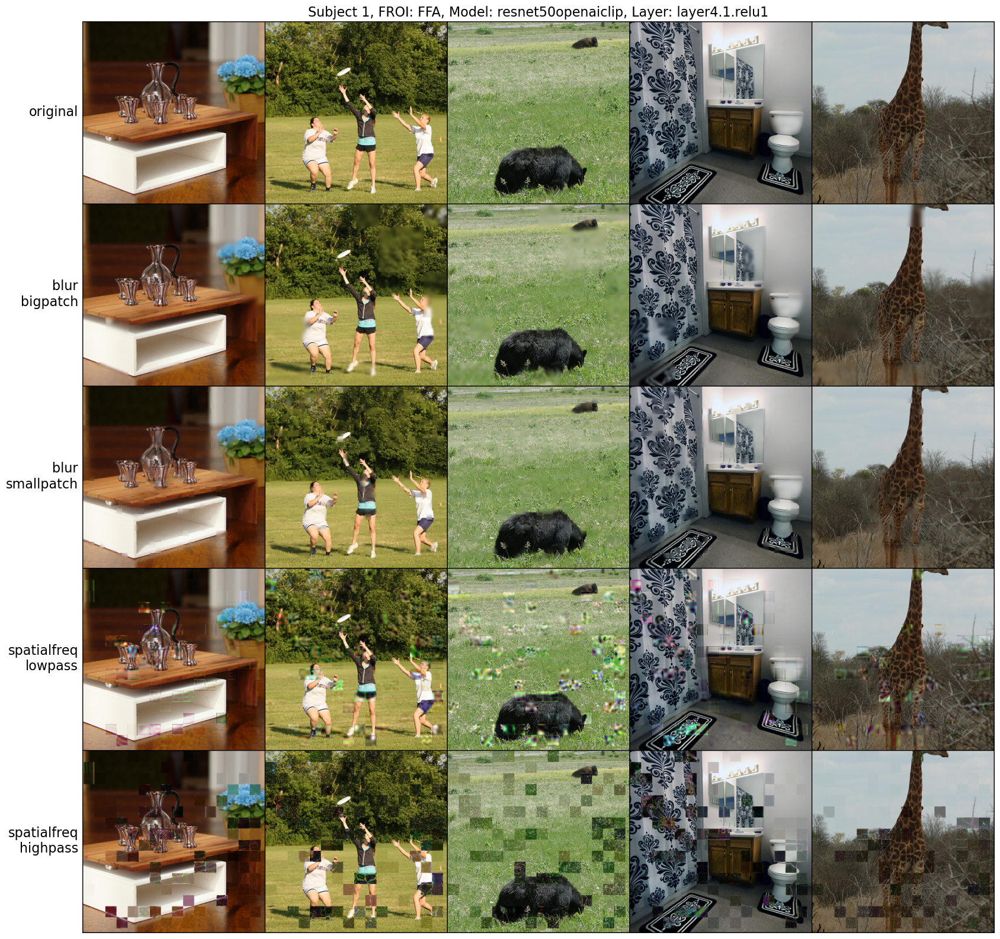

In [90]:
# Using torchvision grid, plot the first 20 images for both original and blurred (in separate subplots)
n_plot = 5
plt.figure(figsize=(20, 20))
plt.axis('off')
combined_list = []
for manipulation in manipulation_types:
    for i in range(n_plot):
        combined_list.append(images_db[i][manipulation])
plt.imshow(np.transpose(vutils.make_grid(
    torch.FloatTensor(combined_list).permute(0, 3, 1, 2), 
    nrow=n_plot, padding=2, normalize=True
), (1, 2, 0)))
# Add row names to show manipulation type
for i, manipulation in enumerate(manipulation_types):
    plt.text(-10, i * (425 + 2) + 212, manipulation.replace('_', '\n'), fontsize=16, va='center', ha='right')
plt.title(f'Subject {subject}, FROI: {froi}, Model: {model_name}, Layer: {layer}', fontsize=16)
# plt.savefig(os.path.join(PLOTS_DIR, f'subj{subject}_{froi}_{model_name}_{layer}_manipulations.png, bbox_inches="tight"))
plt.show()

In [91]:
# Loop over images and get stats and EM predictions
manipulation_preds = {
    k: [] for k in manipulation_types
}

for image_info in images_db:
    for manipulation in manipulation_types:
        img = image_info[manipulation]
        # Get EM prediction
        img_em_pred = get_em_prediction(img, em)
        manipulation_preds[manipulation].append(img_em_pred)

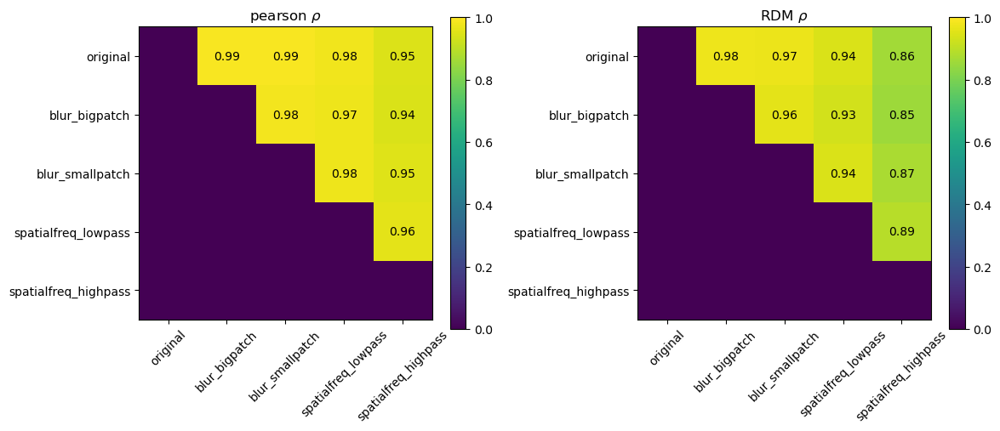

In [92]:
# Make two heatmaps of the pearsonr and rdmr between the original and each manipulation, compute only the upper triangle and show only that
pearsonr_values = np.zeros((len(manipulation_types), len(manipulation_types)))
rdmr_values = np.zeros((len(manipulation_types), len(manipulation_types)))
for i1 in range(len(manipulation_types)):
    for i2 in range(i1 + 1, len(manipulation_types)):
        m1 = manipulation_types[i1]
        m2 = manipulation_types[i2]
        preds1 = torch.stack(manipulation_preds[m1])
        preds2 = torch.stack(manipulation_preds[m2])
        pearsonr = rc_utils.pearsonr(preds1.mean(axis=-1), preds2.mean(axis=-1))
        rdmr = rc_utils.rdmr(preds1, preds2)
        pearsonr_values[i1, i2] = pearsonr
        rdmr_values[i1, i2] = rdmr
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.title(r'pearson $\rho$')
plt.imshow(pearsonr_values, vmin=0, vmax=1, cmap='viridis')
plt.colorbar()
plt.xticks(range(len(manipulation_types)), manipulation_types, rotation=45)
plt.yticks(range(len(manipulation_types)), manipulation_types)
for i in range(len(manipulation_types)):
    for j in range(len(manipulation_types)):
        if i < j:
            plt.text(j, i, f'{pearsonr_values[i, j]:.2f}', ha='center', va='center', color='white' if pearsonr_values[i, j] < 0.5 else 'black')
plt.subplot(1, 2, 2)
plt.title(r'RDM $\rho$')
plt.imshow(rdmr_values, vmin=0, vmax=1, cmap='viridis')
plt.colorbar()
plt.xticks(range(len(manipulation_types)), manipulation_types, rotation=45)
plt.yticks(range(len(manipulation_types)), manipulation_types)
for i in range(len(manipulation_types)):
    for j in range(len(manipulation_types)):
        if i < j:
            plt.text(j, i, f'{rdmr_values[i, j]:.2f}', ha='center', va='center', color='white' if rdmr_values[i, j] < 0.5 else 'black')
plt.tight_layout()
plt.show()

## Dev: Individual images visualization

<Figure size 300x300 with 0 Axes>

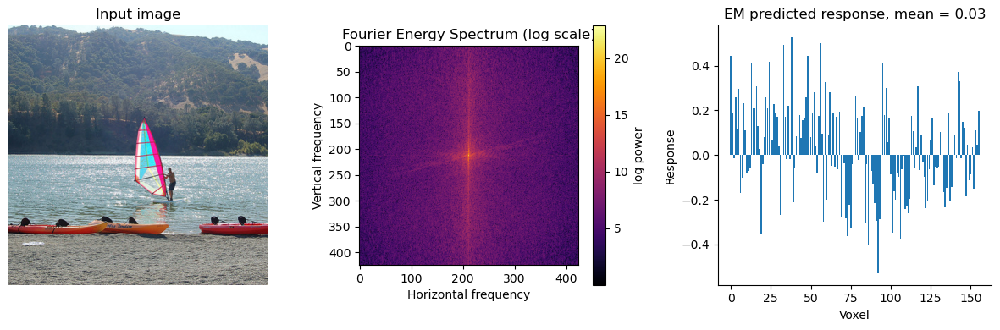

In [ ]:
img_idx = 1
img = stimuli_ds.all_stimuli[img_idx]
# Estimate low-level image statistics
stats, img_energy = compute_low_level_stats(img, return_energy=True)

# Get EM prediction and plot
img_em_pred = get_em_prediction(img, em)
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(img)
plt.axis('off')
plt.title('Input image')
plt.subplot(1,3,2)
plt.imshow(img_energy, cmap='inferno')
plt.title("Fourier Energy Spectrum (log scale)")
plt.xlabel("Horizontal frequency")
plt.ylabel("Vertical frequency")
plt.colorbar(label="log power")
plt.subplot(1,3,3)
plt.bar(np.arange(len(img_em_pred)), img_em_pred)
plt.title(f'EM predicted response, mean = {img_em_pred.mean():.2f}')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.xlabel('Voxel')
plt.ylabel('Response')
plt.tight_layout()
plt.show()
plt.close()

<Figure size 300x300 with 0 Axes>

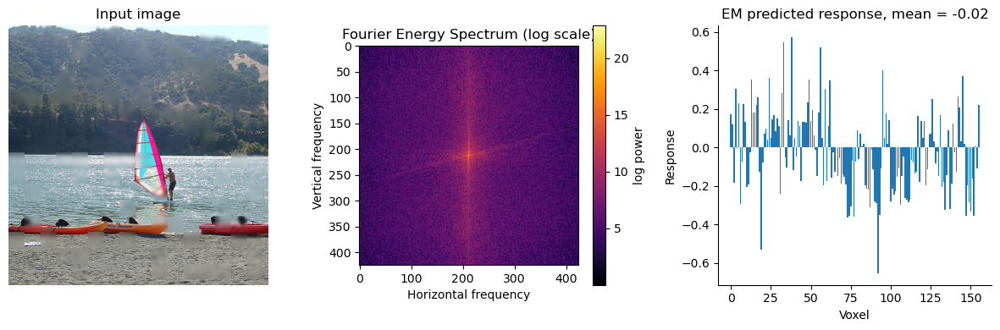

In [21]:
img_blurred = probabilistic_patch_blur(img)

# Estimate low-level image statistics
stats, img_energy = compute_low_level_stats(img_blurred, return_energy=True)

# Get EM prediction and plot
img_em_pred = get_em_prediction(img_blurred, em)
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(img_blurred)
plt.axis('off')
plt.title('Input image')
plt.subplot(1,3,2)
plt.imshow(img_energy, cmap='inferno')
plt.title("Fourier Energy Spectrum (log scale)")
plt.xlabel("Horizontal frequency")
plt.ylabel("Vertical frequency")
plt.colorbar(label="log power")
plt.subplot(1,3,3)
plt.bar(np.arange(len(img_em_pred)), img_em_pred)
plt.title(f'EM predicted response, mean = {img_em_pred.mean():.2f}')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.xlabel('Voxel')
plt.ylabel('Response')
plt.tight_layout()
plt.show()
plt.close()

# Flip-tilt

In [141]:
import numpy as np
from PIL import Image, ImageDraw
import random
import math
import cv2
from scipy.interpolate import splprep, splev

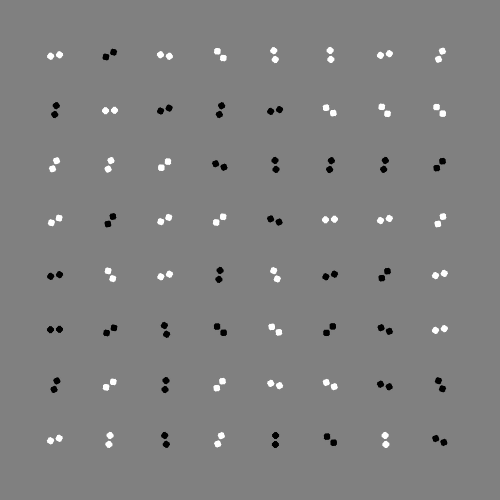

In [ ]:
def generate_stimulus_lowres(n=5, img_size=500, circle_radius=15, gap=5, seed=42):
    """
    Generate an nxn grid of joint-circle stimuli on a gray background.
    
    Args:
        n (int): grid size (n x n points).
        img_size (int): size of square image in pixels.
        circle_radius (int): radius of each circle.
        gap (int): distance between circle centers in the "8".
        seed (int): optional, random seed for reproducibility.
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
    
    # Background (gray)
    img = Image.new("RGB", (img_size, img_size), (128, 128, 128))
    draw = ImageDraw.Draw(img)

    # Grid coordinates
    margin = img_size // (n + 1)
    coords = [(margin*(i+1), margin*(j+1)) for i in range(n) for j in range(n)]

    for (x, y) in coords:
        # Choose color (black or white)
        color = (0, 0, 0) if random.random() < 0.5 else (255, 255, 255)
        
        # Create small canvas for the joint circles
        pair_size = 2 * circle_radius + gap
        pair_img = Image.new("RGBA", (pair_size*2, pair_size*2), (0, 0, 0, 0))
        pair_draw = ImageDraw.Draw(pair_img)

        cx, cy = pair_img.size[0]//2, pair_img.size[1]//2
        
        # Draw two circles side by side (horizontal "8")
        offsets = [-gap//2 - circle_radius, +gap//2 + circle_radius]
        for dx in offsets:
            pair_draw.ellipse(
                (cx+dx-circle_radius, cy-circle_radius,
                 cx+dx+circle_radius, cy+circle_radius),
                fill=color
            )
        
        # Rotate randomly
        angle = random.uniform(0, 360)
        rotated = pair_img.rotate(angle, resample=Image.BICUBIC, expand=True)
        
        # Paste onto main canvas
        img.paste(rotated, (x-rotated.size[0]//2, y-rotated.size[1]//2), rotated)

    return img

# Example usage
stim = generate_stimulus_lowres(n=8, img_size=500, circle_radius=3, gap=3, seed=42)
display(stim)

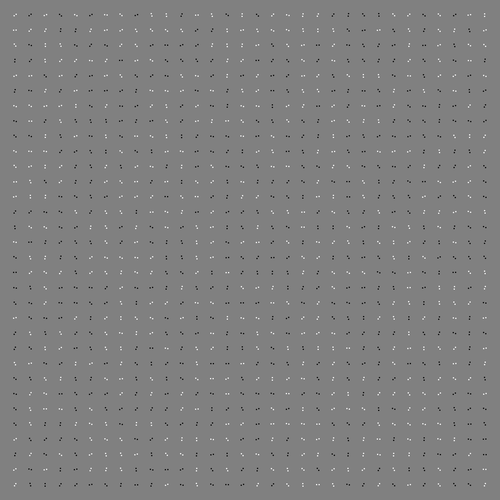

In [40]:
def generate_stimulus(n=5, img_size=500, circle_radius=15.0, gap=5.0, seed=None, oversample=4):
    """
    Generate an nxn grid of joint-circle stimuli on a gray background.
    Allows float values for circle radius and gap.
    Oversampling helps preserve circle shapes when rotating.
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
    
    # Work in higher resolution (float-friendly)
    big_size = int(img_size * oversample)
    big_circle_radius = float(circle_radius) * oversample
    big_gap = float(gap) * oversample
    
    # Background (gray)
    big_img = Image.new("RGB", (big_size, big_size), (128, 128, 128))
    
    # Grid coordinates
    margin = big_size / (n + 1)
    coords = [(margin*(i+1), margin*(j+1)) for i in range(n) for j in range(n)]

    for (x, y) in coords:
        # Choose color (black or white)
        color = (0, 0, 0) if random.random() < 0.5 else (255, 255, 255)
        
        # Canvas for the pair
        pair_size = int(round(2 * big_circle_radius + big_gap))
        pair_img = Image.new("RGBA", (pair_size*2, pair_size*2), (0, 0, 0, 0))
        pair_draw = ImageDraw.Draw(pair_img)

        cx, cy = pair_img.size[0] / 2, pair_img.size[1] / 2
        
        # Draw two circles side by side
        offsets = [-big_gap/2 - big_circle_radius, +big_gap/2 + big_circle_radius]
        for dx in offsets:
            pair_draw.ellipse(
                (cx+dx-big_circle_radius, cy-big_circle_radius,
                 cx+dx+big_circle_radius, cy+big_circle_radius),
                fill=color
            )
        
        # Rotate randomly
        angle = random.uniform(0, 360)
        rotated = pair_img.rotate(angle, resample=Image.BICUBIC, expand=True)
        
        # Paste onto big canvas (convert coords to int)
        big_img.paste(rotated, (int(x - rotated.size[0]/2), int(y - rotated.size[1]/2)), rotated)

    # Downsample to final size (antialiasing keeps circles clean)
    img = big_img.resize((img_size, img_size), Image.LANCZOS)
    return img

# Example stimulus
stim = generate_stimulus(n=32, img_size=500, circle_radius=0.5, gap=1.5)
display(stim)

In [ ]:
def get_mask_contour(mask_path, target_shape=None):
    """
    Loads a mask, finds the main contour, and optionally scales it to a target shape.

    Args:
        mask_path (str): Path to the segmentation mask image.
        target_shape (tuple, optional): The target (height, width) to scale the 
                                         contour to. If None, no scaling is performed.
                                         Defaults to None.
    Returns:
        np.array: A NumPy array of shape (N, 2) containing the scaled contour points.
    """
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        print(f"Warning: Could not load mask at {mask_path}. Skipping.")
        return np.array([]) # Return an empty array if mask is not found

    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    
    # Use CHAIN_APPROX_NONE to get all points for better precision later
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    if not contours:
        print(f"Warning: No contours found in {mask_path}.")
        return np.array([])

    main_contour = max(contours, key=cv2.contourArea)
    
    # --- SCALING LOGIC ---
    # If a target_shape is provided, scale the contour before returning
    if target_shape:
        mask_h, mask_w = mask.shape[:2]
        target_h, target_w = target_shape
        
        # Avoid division by zero if mask is empty
        if mask_w == 0 or mask_h == 0:
            return np.array([])
            
        scale_x = target_w / mask_w
        scale_y = target_h / mask_h
        
        # Apply scaling to the main_contour object
        # The result must be an integer for pixel coordinates.
        main_contour = (main_contour * np.array([scale_x, scale_y])).astype(np.int32)
    # --- END SCALING LOGIC ---

    # Squeeze the final (potentially scaled) contour into an (N, 2) array
    contour_points = main_contour.squeeze()
    return contour_points


def sample_contour_with_angles(contour, num_points):
    """
    Samples points uniformly along a contour and returns their coordinates and the
    angle of the contour's tangent at that point.
    (This function does not need to be changed.)
    """
    # This function is identical to the one you provided.
    # ... (full function code from your prompt) ...
    if contour.ndim == 1 or contour.shape[0] < 3: # Handle empty or too small contours
        return np.array([]), np.array([])

    # Ensure the contour is in the format needed for arcLength if it was squeezed
    if contour.ndim == 2:
        contour = contour.reshape(-1, 1, 2).astype(np.int32)

    contour_points = contour.squeeze()
    N = len(contour_points)
    vertex_tangents = np.zeros_like(contour_points, dtype=float)
    for i in range(N):
        p_prev = contour_points[(i - 1 + N) % N]
        p_curr = contour_points[i]
        p_next = contour_points[(i + 1) % N]
        v_in = p_curr - p_prev
        v_out = p_next - p_curr
        v_in_norm = v_in / (np.linalg.norm(v_in) + 1e-6)
        v_out_norm = v_out / (np.linalg.norm(v_out) + 1e-6)
        tangent = v_in_norm + v_out_norm
        tangent_norm = np.linalg.norm(tangent)
        if tangent_norm > 1e-6:
            vertex_tangents[i] = tangent / tangent_norm
        else:
            vertex_tangents[i] = v_out_norm
    perimeter = cv2.arcLength(contour, True)
    if num_points <= 0: return np.array([]), np.array([])
    distance_between_points = perimeter / num_points
    sampled_points, sampled_tangent_angles = [], []
    cumulative_distance = 0.0
    segment_lengths = [np.linalg.norm(contour_points[i] - contour_points[(i + 1) % N]) for i in range(N)]
    next_sample_dist = 0.0
    for i in range(N):
        segment_start_dist = cumulative_distance
        segment_end_dist = segment_start_dist + segment_lengths[i]
        while next_sample_dist < segment_end_dist and len(sampled_points) < num_points:
            dist_into_segment = next_sample_dist - segment_start_dist
            ratio = dist_into_segment / (segment_lengths[i] + 1e-6)
            p1, p2 = contour_points[i], contour_points[(i + 1) % N]
            new_point = p1 + ratio * (p2 - p1)
            sampled_points.append(new_point.astype(int))
            t1, t2 = vertex_tangents[i], vertex_tangents[(i + 1) % N]
            interp_tangent = (1 - ratio) * t1 + ratio * t2
            final_tangent_vec = interp_tangent / (np.linalg.norm(interp_tangent) + 1e-6)
            angle_rad = np.arctan2(final_tangent_vec[1], final_tangent_vec[0])
            angle_deg = np.degrees(angle_rad)
            if angle_deg < 0: angle_deg += 360
            sampled_tangent_angles.append(angle_deg)
            next_sample_dist += distance_between_points
        cumulative_distance = segment_end_dist
    return np.array(sampled_points), np.array(sampled_tangent_angles)


def stimuli_pipeline(image_index, show_image=False):
    annotation_types = {
        'r_ear': 10, 'r_eye': 5, 'skin': 30, 'nose': 10,
        'mouth': 10, 'l_eye': 5, 'l_ear': 10,
    }
    # Load main image and get its dimensions for scaling
    img_path = f'/om2/user/alishd/github/datasets/CelebaAMask-HQ/CelebAMask-HQ/CelebA-HQ-img/{image_index}.jpg'
    img = Image.open(img_path)
    
    # --- GET TARGET SHAPE FOR SCALING ---
    # The target shape is the shape of the main image we're plotting on.
    # Note: PIL Image shape is (width, height), we need (height, width)
    target_shape = (img.height, img.width)

    ann_folder_idx = image_index // 2000
    img_annotations = [
        f'/om2/user/alishd/github/datasets/CelebaAMask-HQ/CelebAMask-HQ/CelebAMask-HQ-mask-anno/{ann_folder_idx}/{image_index:05d}_{ann_type}.png' 
        for ann_type in list(annotation_types.keys())
    ]
    
    if show_image:
        # (Visualization code for showing masks remains the same)
        plt.figure(figsize=(20, 5))
        plt.subplot(1, len(img_annotations) + 1, 1)
        plt.imshow(img)
        plt.axis('off')
        plt.title('Original image')
        for i, ann_path in enumerate(img_annotations):
            plt.subplot(1, len(img_annotations) + 1, i + 2)
            try:
                ann_img = Image.open(ann_path)
                plt.imshow(ann_img)
            except FileNotFoundError:
                plt.text(0.5, 0.5, 'Not Found', ha='center', va='center')
            plt.axis('off')
            plt.title(list(annotation_types.keys())[i])
        plt.tight_layout()
        plt.show()
        plt.close()
    
    # --- MODIFIED CALL to get_mask_contour ---
    # Pass the target_shape to the function. It will return scaled contours.
    annotation_contours = {
        ann_type: get_mask_contour(ann_path, target_shape=target_shape) 
        for ann_type, ann_path in zip(annotation_types.keys(), img_annotations)
    }

    # The rest of the pipeline works on the already-scaled contours
    annotation_sampled = [
        sample_contour_with_angles(
            contour, annotation_types[ann_type]
        ) for ann_type, contour in annotation_contours.items() if contour.size > 0
    ]

    if show_image:
        # This plotting code will now work correctly because the contour
        # coordinates are in the same space as the main image.
        plt.figure(figsize=(8, 8))
        plt.imshow(img)
        
        for ann_type, contour in annotation_contours.items():
             if contour.size > 0:
                plt.plot(contour[:, 0], contour[:, 1], linewidth=1, alpha=0.5)
        
        colors = plt.cm.get_cmap('tab10', len(annotation_sampled))
        for i, (points, angles) in enumerate(annotation_sampled):
            if points.size > 0:
                plt.scatter(points[:, 0], points[:, 1], color=colors(i), s=40)
                for point, angle in zip(points, angles):
                    angle_rad = np.radians(angle)
                    dx = 10 * np.cos(angle_rad)
                    dy = 10 * np.sin(angle_rad)
                    plt.arrow(point[0], point[1], dx, dy, color=colors(i), width=0.5, head_width=3)
                    
        plt.axis('off')
        plt.title('Scaled Contours and Sampled Points')
        plt.tight_layout()
        plt.show()
        plt.close()

    return img, annotation_contours, annotation_sampled

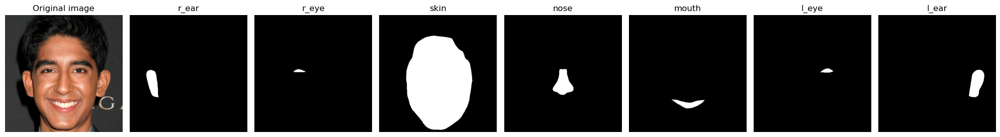

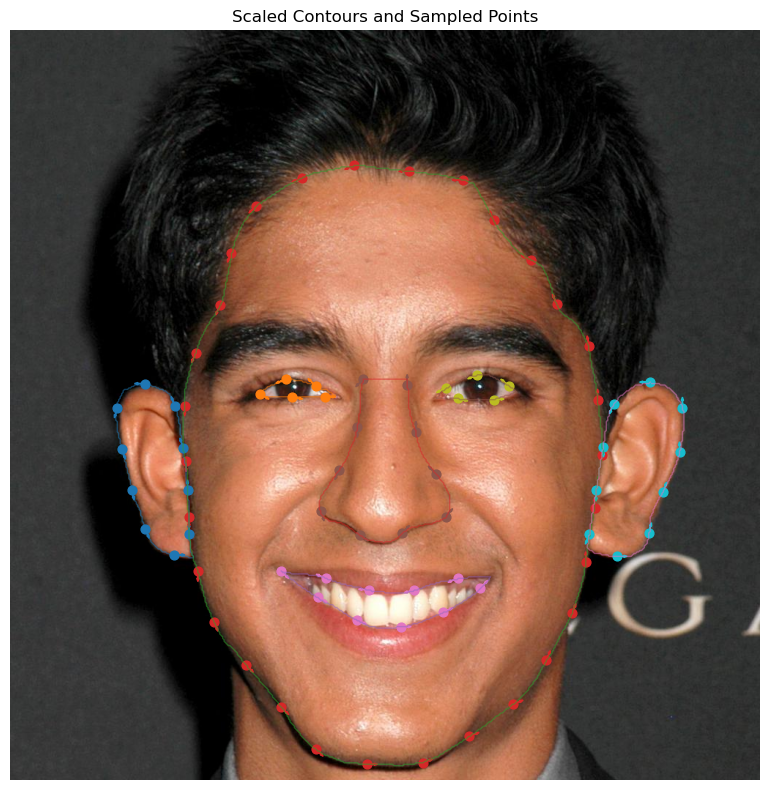

In [117]:
img, xa, xb = pipeline(1170, show_image=True)

In [ ]:
# --- Part 1: Helper Functions ---

def get_mask_contour(mask_path, target_shape=None):
    """
    Loads a mask, finds the main contour, and optionally scales it to a target shape.
    """
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        return np.array([])
    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        return np.array([])
    main_contour = max(contours, key=cv2.contourArea)
    if target_shape:
        mask_h, mask_w = mask.shape[:2]
        target_h, target_w = target_shape
        if mask_w == 0 or mask_h == 0: return np.array([])
        scale_x, scale_y = target_w / mask_w, target_h / mask_h
        main_contour = (main_contour * np.array([scale_x, scale_y])).astype(np.int32)
    return main_contour.squeeze()

def sample_contour_with_angles(contour, num_points, smoothing_factor=10.0):
    """
    Samples points uniformly along a smooth B-spline fitted to a contour and
    returns their coordinates and highly accurate tangent angles from the spline's derivative.

    Args:
        contour (np.array): The contour from cv2.findContours, shape (N, 1, 2).
        num_points (int): The number of points to sample.
        smoothing_factor (float): Controls the smoothness of the fitted spline.
            s=0: The spline passes through all contour points (interpolation).
            s>0: The spline is smoothed, ignoring noise. A larger s means more smoothing.
            Start with s in the range of 1.0 - 5.0 and adjust as needed.

    Returns:
        tuple: A tuple containing:
            - np.array: Shape (num_points, 2), coordinates of the sampled points on the spline.
            - np.array: Shape (num_points,), the tangent angle in degrees [0, 360].
    """
    if contour is None or len(contour) < 4:  # Spline fitting requires at least k+1 points (k=3 for cubic)
        return np.array([]), np.array([])

    # Squeeze contour and get x, y coordinates
    points = contour.squeeze()
    x, y = points[:, 0], points[:, 1]

    # 1. Fit a periodic B-spline to the contour points.
    # 'per=True' is crucial for closed contours.
    # 's' is the smoothing factor.
    # 'k=3' specifies a cubic spline, which is standard for smooth curves.
    tck, u = splprep([x, y], s=smoothing_factor, per=True, k=3)

    # 2. Create a new set of uniformly spaced parameter values for sampling
    u_new = np.linspace(u.min(), u.max(), num_points)

    # 3. Evaluate the spline (and its derivative) at the new points
    # der=0 gives the (x, y) coordinates of the points on the spline
    x_new, y_new = splev(u_new, tck, der=0)
    
    # der=1 gives the first derivative (dx/du, dy/du), which is the tangent vector
    dx, dy = splev(u_new, tck, der=1)

    # 4. Calculate the angle from the tangent vectors
    # Use np.arctan2(dy, dx) for quadrant-correct angles
    angles_rad = np.arctan2(dy, dx)
    angles_deg = np.degrees(angles_rad)
    angles_deg[angles_deg < 0] += 360  # Convert range to [0, 360]

    # 5. Package the results
    sampled_points = np.vstack((x_new, y_new)).T.astype(np.int32)
    
    return sampled_points, angles_deg+90

def create_rotated_pair(angle, color, circle_radius, gap, oversample=4):
    """
    Creates a single, high-quality, rotated 8-shape stimulus on a transparent background.
    """
    big_radius = float(circle_radius) * oversample
    big_gap = float(gap) * oversample
    unrotated_w = 2 * (2 * big_radius) + big_gap
    canvas_size = int(unrotated_w * 1.5)
    pair_img = Image.new("RGBA", (canvas_size, canvas_size), (0, 0, 0, 0))
    draw = ImageDraw.Draw(pair_img)
    cx, cy = canvas_size / 2, canvas_size / 2
    offsets = [-big_gap/2 - big_radius, +big_gap/2 + big_radius]
    for dx in offsets:
        draw.ellipse((cx + dx - big_radius, cy - big_radius,
                      cx + dx + big_radius, cy + big_radius), fill=color)
    return pair_img.rotate(angle, resample=Image.BICUBIC, expand=True)

# --- Part 2: Your Modified Main Pipeline ---

def stimuli_pipeline(
    image_index, 
    num_random_stimuli=50, 
    exclusion_margin_pixels=30,
    circle_radius=10.0, 
    gap=3.0, 
    seed=None,
    use_original_background=True,
    contour_color_mode='random',
    show_intermediate_plots=False
):
    """
    Loads an image and annotations, and generates a final stimulus image.
    Stimuli are placed on feature contours and randomly across the image.

    Args:
        image_index (int): The index of the image to process from the dataset.
        num_random_stimuli (int): Total number of randomly placed stimuli.
        exclusion_margin_pixels (int): The radius of the "keep-out" zone around each
            contour stimulus where random stimuli cannot be placed.
        circle_radius (float): Radius of the individual circles in the 8-shape.
        gap (float): Gap between the two circles.
        seed (int, optional): Random seed for reproducibility.
        use_original_background (bool, optional): If True, uses the original image
            as the background. If False, uses a uniform gray background. Defaults to True.
        contour_color_mode (str, optional): Coloring for contour stimuli.
            'random': Black or white with 50/50 probability.
            'alternating': Alternates between black and white along the contour.
            Defaults to 'random'.
        show_intermediate_plots (bool, optional): If True, displays a plot of the
            contours and sampled points. Defaults to False.

    Returns:1
        PIL.Image.Image: The final generated stimulus image.
    """
    if seed is not None and seed != -1:
        random.seed(seed)
        np.random.seed(seed)

    # No ears for now: r_ear': 10', 'l_ear': 10,
    annotation_types = {
        'r_eye': 20, 'skin': 100, 'nose': 50,
        'mouth': 50, 'l_eye': 20,
    }
    
    # 1. Load background and determine final dimensions
    img_path = f'/om2/user/alishd/github/datasets/CelebaAMask-HQ/CelebAMask-HQ/CelebA-HQ-img/{image_index}.jpg'
    
    with Image.open(img_path) as original_img:
        img_w, img_h = original_img.size
        if use_original_background:
            final_img = original_img.convert("RGB")
        else:
            final_img = Image.new("RGB", (img_w, img_h), (128, 128, 128))
    
    target_shape = (img_h, img_w)

    # 2. Get paths to all annotation masks
    ann_folder_idx = image_index // 2000
    ann_paths = {
        ann_type: f'/om2/user/alishd/github/datasets/CelebaAMask-HQ/CelebAMask-HQ/CelebAMask-HQ-mask-anno/{ann_folder_idx}/{image_index:05d}_{ann_type}.png' 
        for ann_type in annotation_types
    }

    # 3. Get scaled contours and sampled points/angles for each feature
    annotation_sampled = {
        ann_type: sample_contour_with_angles(
            get_mask_contour(path, target_shape=target_shape), 
            annotation_types[ann_type]
        )
        for ann_type, path in ann_paths.items()
    }

    # 4. Create an EXCLUSION MASK based on contour stimuli locations
    exclusion_mask = np.zeros(target_shape, dtype=np.uint8)
    all_contour_points = []
    for points, angles in annotation_sampled.values():
        if len(points) > 0:
            all_contour_points.extend(points)

    if exclusion_margin_pixels > 0:
        for point in all_contour_points:
            cv2.circle(exclusion_mask, tuple(point), int(exclusion_margin_pixels), 255, -1)

    # 5. Generate random points, avoiding the exclusion mask
    random_points = []
    possible_points = np.argwhere(exclusion_mask == 0)
    if len(possible_points) > 0 and num_random_stimuli > 0:
        indices = np.random.choice(len(possible_points), size=num_random_stimuli)
        random_points = [(p[1], p[0]) for p in possible_points[indices]]

    # --- 6. DRAWING PHASE ---

    black = (0, 0, 0)
    white = (255, 255, 255)

    # Draw contour stimuli
    for ann_type, (points, angles) in annotation_sampled.items():
        if len(points) == 0: continue
        for i, (point, angle) in enumerate(zip(points, angles)):
            
            # --- NEW COLOR LOGIC based on contour_color_mode ---
            if contour_color_mode == 'alternating':
                color = black if i % 2 == 0 else white
            else:  # Default to 'random'
                color = black if random.random() < 0.5 else white
            # --- END NEW COLOR LOGIC ---
            
            pair_img = create_rotated_pair(angle + 90, color, circle_radius, gap)
            paste_pos = (point[0] - pair_img.width // 2, point[1] - pair_img.height // 2)
            final_img.paste(pair_img, paste_pos, pair_img)

    # Draw random stimuli (color is always random for these)
    for x, y in random_points:
        color = black if random.random() < 0.5 else white
        angle = random.uniform(0, 360)
        pair_img = create_rotated_pair(angle, color, circle_radius, gap)
        paste_pos = (x - pair_img.width // 2, y - pair_img.height // 2)
        final_img.paste(pair_img, paste_pos, pair_img)

    if show_intermediate_plots:
        print("Displaying intermediate plot of contours and exclusion mask...")
        fig, ax = plt.subplots(1, 2, figsize=(16, 8))
        ax[0].imshow(Image.open(img_path))
        colors = plt.cm.get_cmap('tab10', len(annotation_sampled))
        for i, (ann_type, (points, angles)) in enumerate(annotation_sampled.items()):
            if len(points) > 0:
                ax[0].scatter(points[:, 0], points[:, 1], color=colors(i), s=40, label=ann_type)
        ax[0].legend()
        ax[0].set_title("Sampled Contour Points")
        ax[0].axis('off')
        
        ax[1].imshow(exclusion_mask, cmap='gray')
        ax[1].set_title("Exclusion Mask for Random Points")
        ax[1].axis('off')
        plt.show()

    return final_img

In [185]:
# --- Part 1: Helper Functions ---

def get_mask_contour(mask_path, target_shape=None):
    """
    Loads a mask, finds the main contour, and optionally scales it to a target shape.
    """
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        return np.array([])
    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        return np.array([])
    main_contour = max(contours, key=cv2.contourArea)
    if target_shape:
        mask_h, mask_w = mask.shape[:2]
        target_h, target_w = target_shape
        if mask_w == 0 or mask_h == 0: return np.array([])
        scale_x, scale_y = target_w / mask_w, target_h / mask_h
        main_contour = (main_contour * np.array([scale_x, scale_y])).astype(np.int32)
    
    # This now returns a squeezed contour of shape (N, 2), ready for the spline function
    return main_contour.squeeze()

def sample_contour_with_angles(contour, num_points, smoothing_factor=10.0):
    """
    Samples points along a smooth spline and returns their coordinates and the
    angle NORMAL (perpendicular) to the contour's tangent.

    Args:
        contour (np.array): A contour of shape (N, 2).
        num_points (int): The number of points to sample.
        smoothing_factor (float): Controls the smoothness of the fitted spline.

    Returns:
        tuple: (sampled_points, normal_angles_degrees)
    """
    # Spline fitting requires at least k+1 points (k=3 for cubic) and a non-empty array
    if contour is None or contour.shape[0] < 4:
        return np.array([]), np.array([])

    points = contour
    x, y = points[:, 0], points[:, 1]
    
    # Fit a periodic B-spline to the contour points.
    tck, u = splprep([x, y], s=smoothing_factor, per=True, k=3)

    # Evaluate the spline at new, uniformly spaced points
    u_new = np.linspace(u.min(), u.max(), num_points)
    x_new, y_new = splev(u_new, tck, der=0)
    
    # Get the derivative (tangent vector)
    dx, dy = splev(u_new, tck, der=1)

    # Calculate the tangent angle and convert to degrees [0, 360]
    angles_rad = np.arctan2(dy, dx)
    angles_deg = np.degrees(angles_rad)
    angles_deg[angles_deg < 0] += 360

    sampled_points = np.vstack((x_new, y_new)).T.astype(np.int32)
    
    # Return the NORMAL angle (tangent + 90 degrees)
    return sampled_points, (angles_deg) % 360

def create_rotated_pair(angle, colors, circle_radius, gap, oversample=4):
    """
    Creates a single, high-quality, rotated 8-shape stimulus.
    Accepts a tuple of two colors for the left and right circles.
    """
    # If a single color is passed (for random stimuli), use it for both circles
    if not isinstance(colors, (list, tuple)):
        colors = (colors, colors)

    big_radius = float(circle_radius) * oversample
    big_gap = float(gap) * oversample
    unrotated_w = 2 * (2 * big_radius) + big_gap
    canvas_size = int(unrotated_w * 1.5)
    
    pair_img = Image.new("RGBA", (canvas_size, canvas_size), (0, 0, 0, 0))
    draw = ImageDraw.Draw(pair_img)
    
    cx, cy = canvas_size / 2, canvas_size / 2
    
    # Define offsets and draw each circle with its specified color
    offsets = [-big_gap/2 - big_radius, +big_gap/2 + big_radius]
    for i, dx in enumerate(offsets):
        draw.ellipse((cx + dx - big_radius, cy - big_radius,
                      cx + dx + big_radius, cy + big_radius), fill=colors[i])
    
    return pair_img.rotate(angle, resample=Image.BICUBIC, expand=True)

# --- Part 2: The Main Stimulus Pipeline ---

def stimuli_pipeline(
    image_index, 
    num_random_stimuli=50, 
    exclusion_margin_pixels=30,
    circle_radius=10.0, 
    gap=3.0, 
    seed=None,
    use_original_background=True,
    contour_color_mode='random',
    smoothing_factor=10.0,
    show_intermediate_plots=False
):
    """
    Loads an image and annotations, and generates a final stimulus image.

    Args:
        image_index (int): The index of the image to process from the dataset.
        num_random_stimuli (int): Total number of randomly placed stimuli.
        exclusion_margin_pixels (int): Radius of the "keep-out" zone around contour stimuli.
        circle_radius (float): Radius of the circles in the 8-shape.
        gap (float): Gap between the circles.
        seed (int, optional): Random seed for reproducibility.
        use_original_background (bool, optional): If True, use original image background.
            If False, use a gray background.
        contour_color_mode (str, optional): Coloring for contour stimuli.
            'random': Black or white with 50/50 probability.
            'alternating': Alternates between black and white.
            'fliptilt': Cycles through (W,W), (B,W), (B,B), (W,B).
        smoothing_factor (float, optional): Controls spline smoothness for tangent estimation.
        show_intermediate_plots (bool, optional): If True, display intermediate plots.

    Returns:
        PIL.Image.Image: The final generated stimulus image.
    """
    if seed is not None and seed != -1:
        random.seed(seed)
        np.random.seed(seed)

    annotation_types = {
        'r_eye': 15, 'skin': 90, 'nose': 40,
        'mouth': 35, 'l_eye': 15,
    }
    
    img_path = f'/om2/user/alishd/github/datasets/CelebaAMask-HQ/CelebAMask-HQ/CelebA-HQ-img/{image_index}.jpg'
    
    with Image.open(img_path) as original_img:
        img_w, img_h = original_img.size
        if use_original_background:
            final_img = original_img.convert("RGB")
        else:
            final_img = Image.new("RGB", (img_w, img_h), (128, 128, 128))
    
    target_shape = (img_h, img_w)

    ann_folder_idx = image_index // 2000
    ann_paths = {
        ann_type: f'/om2/user/alishd/github/datasets/CelebaAMask-HQ/CelebAMask-HQ/CelebAMask-HQ-mask-anno/{ann_folder_idx}/{image_index:05d}_{ann_type}.png' 
        for ann_type in annotation_types
    }

    annotation_sampled = {
        ann_type: sample_contour_with_angles(
            get_mask_contour(path, target_shape=target_shape), 
            annotation_types[ann_type],
            smoothing_factor=smoothing_factor
        )
        for ann_type, path in ann_paths.items()
    }

    exclusion_mask = np.zeros(target_shape, dtype=np.uint8)
    all_contour_points = []
    for points, angles in annotation_sampled.values():
        if len(points) > 0:
            all_contour_points.extend(points)

    if exclusion_margin_pixels > 0 and len(all_contour_points) > 0:
        for point in all_contour_points:
            cv2.circle(exclusion_mask, tuple(point), int(exclusion_margin_pixels), 255, -1)
            
    random_points = []
    possible_points = np.argwhere(exclusion_mask == 0)
    if len(possible_points) > 0 and num_random_stimuli > 0:
        indices = np.random.choice(len(possible_points), size=num_random_stimuli)
        random_points = [(p[1], p[0]) for p in possible_points[indices]]

    # --- DRAWING PHASE ---
    black = (0, 0, 0)
    white = (255, 255, 255)

    # Draw contour stimuli
    for ann_type, (points, angles) in annotation_sampled.items():
        if len(points) == 0: continue
        for i, (point, angle) in enumerate(zip(points, angles)):
            colors_for_pair = None
            if contour_color_mode == 'alternating':
                color = black if i % 2 == 0 else white
                colors_for_pair = (color, color)
            elif contour_color_mode == 'fliptilt':
                state = i % 4
                if state == 0: colors_for_pair = (white, white)
                elif state == 1: colors_for_pair = (black, white)
                elif state == 2: colors_for_pair = (black, black)
                else: colors_for_pair = (white, black)
            else: # Default 'random'
                color = black if random.random() < 0.5 else white
                colors_for_pair = (color, color)
            
            # The angle is now the NORMAL angle, so we use it directly
            pair_img = create_rotated_pair(angle, colors_for_pair, circle_radius, gap)
            paste_pos = (point[0] - pair_img.width // 2, point[1] - pair_img.height // 2)
            final_img.paste(pair_img, paste_pos, pair_img)

    # Draw random stimuli
    for x, y in random_points:
        color = black if random.random() < 0.5 else white
        angle = random.uniform(0, 360)
        # Pass a tuple of colors to the updated function
        pair_img = create_rotated_pair(angle, (color, color), circle_radius, gap)
        paste_pos = (x - pair_img.width // 2, y - pair_img.height // 2)
        final_img.paste(pair_img, paste_pos, pair_img)

    if show_intermediate_plots:
        fig, ax = plt.subplots(1, 2, figsize=(16, 8))
        ax[0].imshow(Image.open(img_path))
        colors = plt.cm.get_cmap('tab10', len(annotation_sampled))
        for i, (ann_type, (points, angles)) in enumerate(annotation_sampled.items()):
            if len(points) > 0:
                ax[0].scatter(points[:, 0], points[:, 1], color=colors(i), s=40, label=ann_type)
        ax[0].legend()
        ax[0].set_title("Sampled Contour Points")
        ax[0].axis('off')
        
        ax[1].imshow(exclusion_mask, cmap='gray')
        ax[1].set_title("Exclusion Mask for Random Points")
        ax[1].axis('off')
        plt.show()

    return final_img

In [212]:
# --- Part 1: Helper Functions ---

def get_mask_contour(mask_path, target_shape=None, return_squeezed=True):
    """
    Loads a mask, finds the main contour, optionally scales it, and returns it.

    Args:
        mask_path (str): Path to the segmentation mask image.
        target_shape (tuple, optional): The target (height, width) to scale the 
                                         contour to. If None, no scaling is performed.
        return_squeezed (bool): If True, returns shape (N,2). If False, returns
                                OpenCV's native (N,1,2) shape.
    
    Returns:
        np.array: The main contour found in the image.
    """
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        return np.array([]) if return_squeezed else np.array([]).reshape(0, 1, 2)

    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    if not contours:
        return np.array([]) if return_squeezed else np.array([]).reshape(0, 1, 2)

    main_contour = max(contours, key=cv2.contourArea)
    
    if target_shape:
        mask_h, mask_w = mask.shape[:2]
        target_h, target_w = target_shape
        if mask_w == 0 or mask_h == 0:
            return np.array([]) if return_squeezed else np.array([]).reshape(0, 1, 2)
        scale_x, scale_y = target_w / mask_w, target_h / mask_h
        main_contour = (main_contour * np.array([scale_x, scale_y])).astype(np.int32)

    return main_contour.squeeze() if return_squeezed else main_contour

def sample_smooth_contour_with_spline(contour, num_points, smoothing_factor=1.0):
    """
    Samples points uniformly along a smooth B-spline fitted to a contour and
    returns their coordinates and highly accurate tangent angles from the spline's derivative.
    """
    if contour is None or len(contour) < 4:
        return np.array([]), np.array([])
    if contour.ndim == 2:
        contour = contour.reshape(-1, 1, 2).astype(np.int32)
        
    points = contour.squeeze()
    x, y = points[:, 0], points[:, 1]
    
    tck, u = splprep([x, y], s=smoothing_factor, per=True, k=3)
    
    u_new = np.linspace(u.min(), u.max(), num_points)
    x_new, y_new = splev(u_new, tck, der=0)
    
    dx, dy = splev(u_new, tck, der=1)

    angles_rad = np.arctan2(dy, dx)
    angles_deg = np.degrees(angles_rad)
    angles_deg[angles_deg < 0] += 360

    sampled_points = np.vstack((x_new, y_new)).T.astype(np.int32)
    return sampled_points, (angles_deg + 90) % 360 # Return NORMAL angle

def create_rotated_pair(angle, colors, circle_radius, gap, oversample=4):
    """
    Creates a single, high-quality, rotated 8-shape stimulus.
    Accepts a tuple of two colors for the left and right circles.
    """
    if not isinstance(colors, (list, tuple)):
        colors = (colors, colors)
        
    big_radius = float(circle_radius) * oversample
    big_gap = float(gap) * oversample
    unrotated_w = 2 * (2 * big_radius) + big_gap
    canvas_size = int(unrotated_w * 1.5)
    
    pair_img = Image.new("RGBA", (canvas_size, canvas_size), (0, 0, 0, 0))
    draw = ImageDraw.Draw(pair_img)
    
    cx, cy = canvas_size / 2, canvas_size / 2
    
    offsets = [-big_gap/2 - big_radius, +big_gap/2 + big_radius]
    for i, dx in enumerate(offsets):
        draw.ellipse((cx + dx - big_radius, cy - big_radius,
                      cx + dx + big_radius, cy + big_radius), fill=colors[i])
    
    return pair_img.rotate(angle, resample=Image.BICUBIC, expand=True)

# --- Part 2: The Main Stimulus Pipeline ---

def stimuli_pipeline(
    image_index, 
    num_random_stimuli=50, 
    exclusion_margin_pixels=30,
    circle_radius=10.0, 
    gap=3.0, 
    seed=None,
    use_original_background=True,
    contour_color_mode='random',
    smoothing_factor=3.0,
    show_intermediate_plots=False
):
    """
    Loads an image and annotations, and generates a final stimulus image.

    Args:
        image_index (int): The index of the image to process from the dataset.
        num_random_stimuli (int): Total number of randomly placed stimuli.
        exclusion_margin_pixels (int): Radius of the "keep-out" zone around contour stimuli.
        circle_radius (float): Radius of the circles in the 8-shape.
        gap (float): Gap between the circles.
        seed (int, optional): Random seed for reproducibility.
        use_original_background (bool, optional): If True, use original image background.
            If False, use a gray background.
        contour_color_mode (str, optional): Coloring for contour stimuli.
            'random': Black or white with 50/50 probability.
            'alternating': Alternates between black and white.
            'fliptilt': Cycles through (W,W), (B,W), (B,B), (W,B).
            'control': Does not draw contour stimuli, only random stimuli.
        smoothing_factor (float, optional): Controls spline smoothness for tangent estimation.
        show_intermediate_plots (bool, optional): If True, display intermediate plots.

    Returns:
        PIL.Image.Image: The final generated stimulus image.
    """
    if seed is not None and seed != -1:
        random.seed(seed)
        np.random.seed(seed)

    annotation_types = {
        'r_eye': 20, 'skin': 90, 'nose': 40,
        'mouth': 35, 'l_eye': 20,
    }
    
    img_path = f'/om2/user/alishd/github/datasets/CelebaAMask-HQ/CelebAMask-HQ/CelebA-HQ-img/{image_index}.jpg'
    
    with Image.open(img_path) as original_img:
        img_w, img_h = original_img.size
        if use_original_background:
            final_img = original_img.convert("RGB")
        else:
            final_img = Image.new("RGB", (img_w, img_h), (128, 128, 128))
    
    target_shape = (img_h, img_w)

    ann_folder_idx = image_index // 2000
    ann_paths = {
        ann_type: f'/om2/user/alishd/github/datasets/CelebaAMask-HQ/CelebAMask-HQ/CelebAMask-HQ-mask-anno/{ann_folder_idx}/{image_index:05d}_{ann_type}.png' 
        for ann_type in annotation_types
    }

    annotation_sampled = {
        ann_type: sample_smooth_contour_with_spline(
            get_mask_contour(path, target_shape=target_shape, return_squeezed=False), 
            annotation_types[ann_type],
            smoothing_factor=smoothing_factor
        )
        for ann_type, path in ann_paths.items()
    }
    
    exclusion_mask = np.zeros(target_shape, dtype=np.uint8)
    all_contour_points = []
    for points, angles in annotation_sampled.values():
        if len(points) > 0:
            all_contour_points.extend(points)

    if exclusion_margin_pixels > 0 and len(all_contour_points) > 0:
        for point in all_contour_points:
            cv2.circle(exclusion_mask, tuple(point), int(exclusion_margin_pixels), 255, -1)
            
    random_points = []
    possible_points = np.argwhere(exclusion_mask == 0)
    if len(possible_points) > 0 and num_random_stimuli > 0:
        indices = np.random.choice(len(possible_points), size=num_random_stimuli)
        random_points = [(p[1], p[0]) for p in possible_points[indices]]

    # --- DRAWING PHASE ---
    black = (0, 0, 0)
    white = (255, 255, 255)

    # Draw contour stimuli UNLESS in 'control' mode
    if contour_color_mode != 'control':
        for ann_type, (points, angles) in annotation_sampled.items():
            if len(points) == 0: continue
            for i, (point, angle) in enumerate(zip(points, angles)):
                colors_for_pair = None
                if contour_color_mode == 'alternating':
                    color = black if i % 2 == 0 else white
                    colors_for_pair = (color, color)
                elif contour_color_mode == 'fliptilt':
                    state = i % 4
                    if state == 0: colors_for_pair = (white, white)
                    elif state == 1: colors_for_pair = (black, white)
                    elif state == 2: colors_for_pair = (black, black)
                    else: colors_for_pair = (white, black)
                else: # Default 'random'
                    color = black if random.random() < 0.5 else white
                    colors_for_pair = (color, color)
                
                # The angle is the NORMAL angle, so we use it directly
                pair_img = create_rotated_pair(angle, colors_for_pair, circle_radius, gap)
                paste_pos = (point[0] - pair_img.width // 2, point[1] - pair_img.height // 2)
                final_img.paste(pair_img, paste_pos, pair_img)

    # Draw random stimuli (this happens in all modes)
    for x, y in random_points:
        color = black if random.random() < 0.5 else white
        angle = random.uniform(0, 360)
        pair_img = create_rotated_pair(angle, (color, color), circle_radius, gap)
        paste_pos = (x - pair_img.width // 2, y - pair_img.height // 2)
        final_img.paste(pair_img, paste_pos, pair_img)

    if show_intermediate_plots:
        fig, ax = plt.subplots(1, 2, figsize=(16, 8))
        ax[0].imshow(Image.open(img_path))
        colors = plt.cm.get_cmap('tab10', len(annotation_sampled))
        for i, (ann_type, (points, angles)) in enumerate(annotation_sampled.items()):
            if len(points) > 0:
                ax[0].scatter(points[:, 0], points[:, 1], color=colors(i), s=40, label=ann_type)
        ax[0].legend()
        ax[0].set_title("Sampled Contour Points (Hidden in 'control' mode)")
        ax[0].axis('off')
        
        ax[1].imshow(exclusion_mask, cmap='gray')
        ax[1].set_title("Exclusion Mask (Always Active)")
        ax[1].axis('off')
        plt.show()

    return final_img

In [215]:
image_indices = [112, 116, 154, 1115, 1124, 1170, 1350, 2001, 2020, 2564]

In [216]:
stim_path = '/om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_ems/fliptilt'
os.makedirs(stim_path, exist_ok=True)
# Loop over image indices, for each mode, and generate images
for idx in image_indices:
    for midx, mode in enumerate(['control', 'random', 'alternating', 'fliptilt']):
        print(f"Generating image {idx} in mode '{mode}'...")
        img = stimuli_pipeline(
            idx, 
            num_random_stimuli=1000, 
            exclusion_margin_pixels=10,
            circle_radius=0.25, 
            gap=0.75, 
            seed=42,
            use_original_background=False,
            contour_color_mode=mode,
            smoothing_factor=10.0,
            show_intermediate_plots=False
        )
        output_path = f'{stim_path}/{midx+1}-image_{idx:04d}.png'
        img.save(output_path)
        print(f"Saved to {output_path}")

Generating image 112 in mode 'control'...
Saved to /om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_ems/fliptilt/1-image_0112.png
Generating image 112 in mode 'random'...
Saved to /om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_ems/fliptilt/2-image_0112.png
Generating image 112 in mode 'alternating'...
Saved to /om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_ems/fliptilt/3-image_0112.png
Generating image 112 in mode 'fliptilt'...
Saved to /om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_ems/fliptilt/4-image_0112.png
Generating image 116 in mode 'control'...
Saved to /om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_ems/fliptilt/1-image_0116.png
Generating image 116 in mode 'random'...
Saved to /om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_e

In [ ]:
stim_path = '/om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_ems/fliptilt_noisepts'
os.makedirs(stim_path, exist_ok=True)
n_noise_pts = [1, 50, 100, 500, 1000]
# Loop over image indices, for each mode, and generate images
for idx in image_indices:
    for nidx, n_pts in enumerate(n_noise_pts):
        # print(f"Generating image {idx} in mode '{mode}'...")
        img = stimuli_pipeline(
            idx,
            num_random_stimuli=n_pts, 
            exclusion_margin_pixels=10,
            circle_radius=0.25, 
            gap=0.75, 
            seed=42,
            use_original_background=False,
            contour_color_mode='alternating',
            smoothing_factor=10.0,
            show_intermediate_plots=False
        )
        output_path = f'{stim_path}/{nidx+1}-image_{idx:04d}.png'
        img.save(output_path)
        print(f"Saved to {output_path}")

Generating image 112 in mode 'fliptilt'...
Saved to /om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_ems/fliptilt_noisepts/1-image_0112.png
Generating image 112 in mode 'fliptilt'...
Saved to /om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_ems/fliptilt_noisepts/2-image_0112.png
Generating image 112 in mode 'fliptilt'...
Saved to /om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_ems/fliptilt_noisepts/3-image_0112.png
Generating image 112 in mode 'fliptilt'...
Saved to /om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_ems/fliptilt_noisepts/4-image_0112.png
Generating image 112 in mode 'fliptilt'...
Saved to /om2/user/alishd/github/comparing-category-selectivity/preprint/results/exploration/break_ems/fliptilt_noisepts/5-image_0112.png
Generating image 116 in mode 'fliptilt'...
Saved to /om2/user/alishd/github/comparing-category-

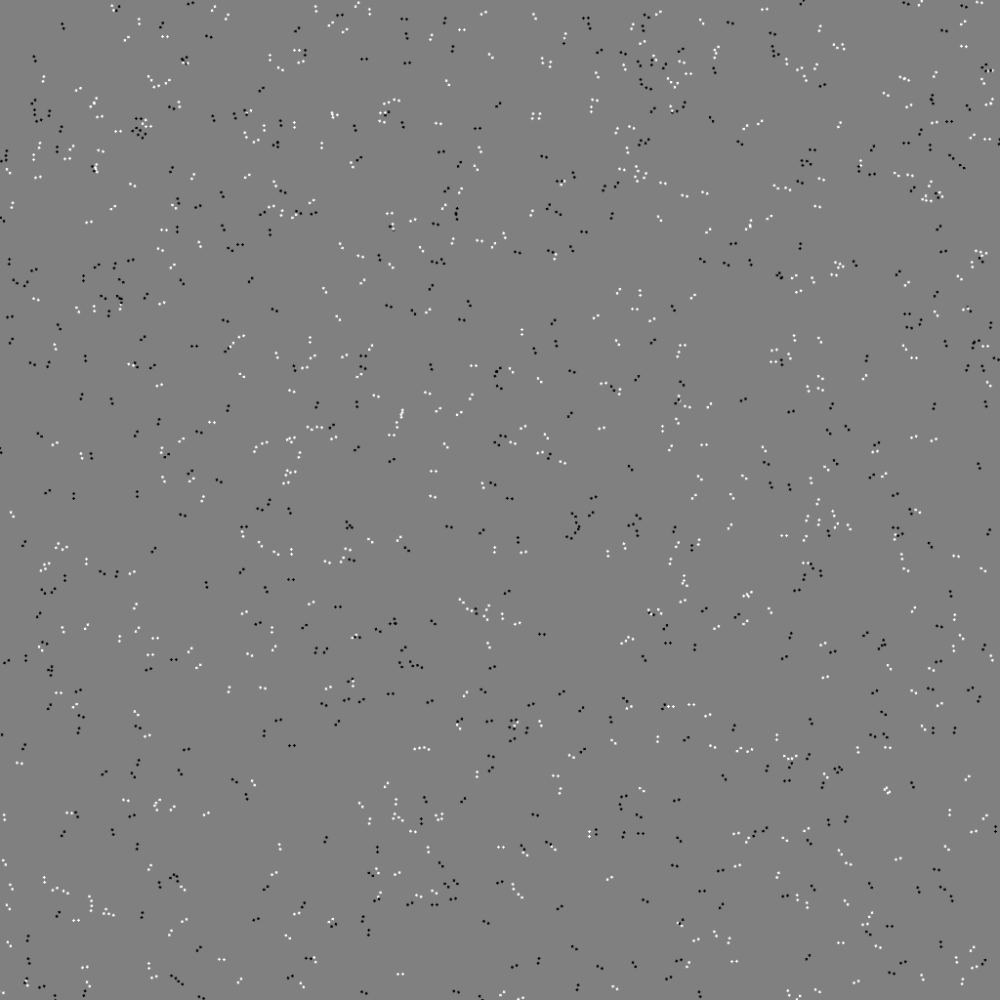

In [202]:
stimuli_pipeline(
    1170, 
    num_random_stimuli=1000, 
    exclusion_margin_pixels=10,
    circle_radius=0.25, 
    gap=0.75, 
    seed=42,
    use_original_background=False,
    contour_color_mode='control',
    smoothing_factor=10.0,
    show_intermediate_plots=False
)

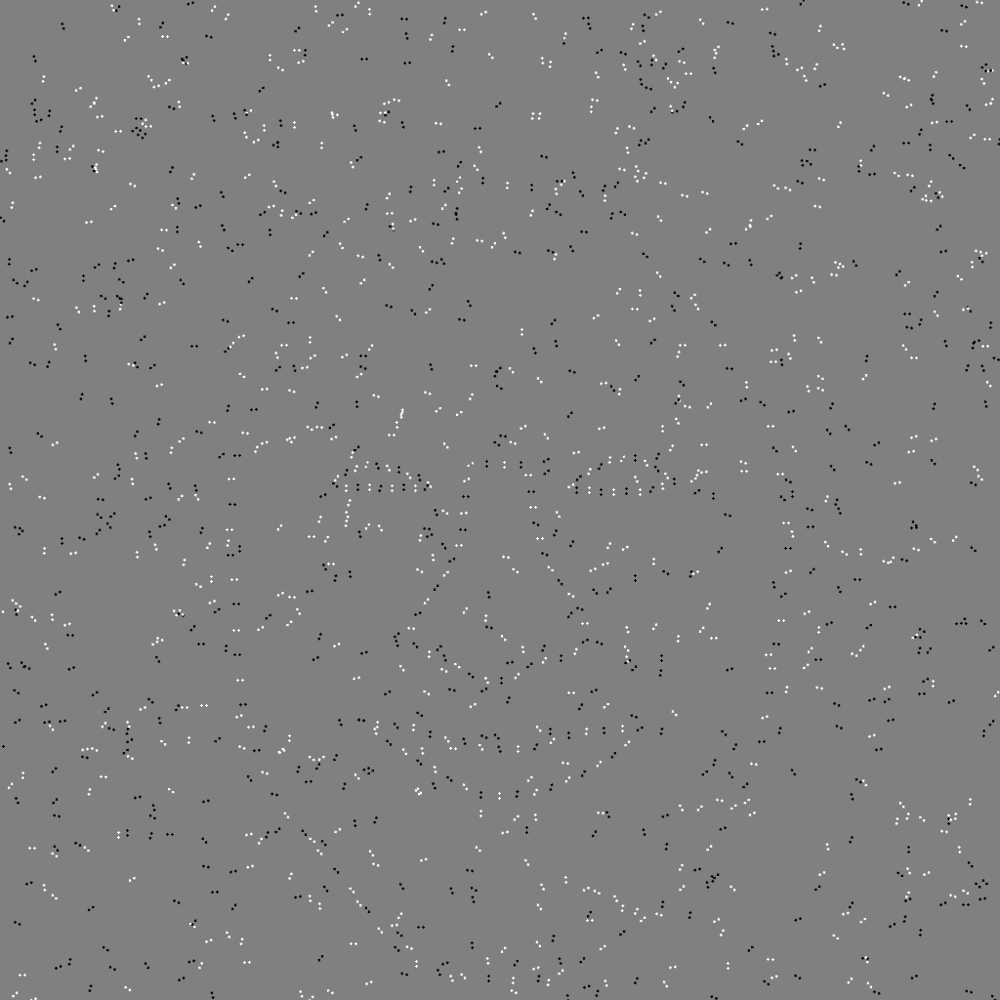

In [210]:
stimuli_pipeline(
    1170, 
    num_random_stimuli=1000, 
    exclusion_margin_pixels=10,
    circle_radius=0.25, 
    gap=0.75, 
    seed=42,
    use_original_background=False,
    contour_color_mode='alternating',
    smoothing_factor=10.0,
    show_intermediate_plots=False
)

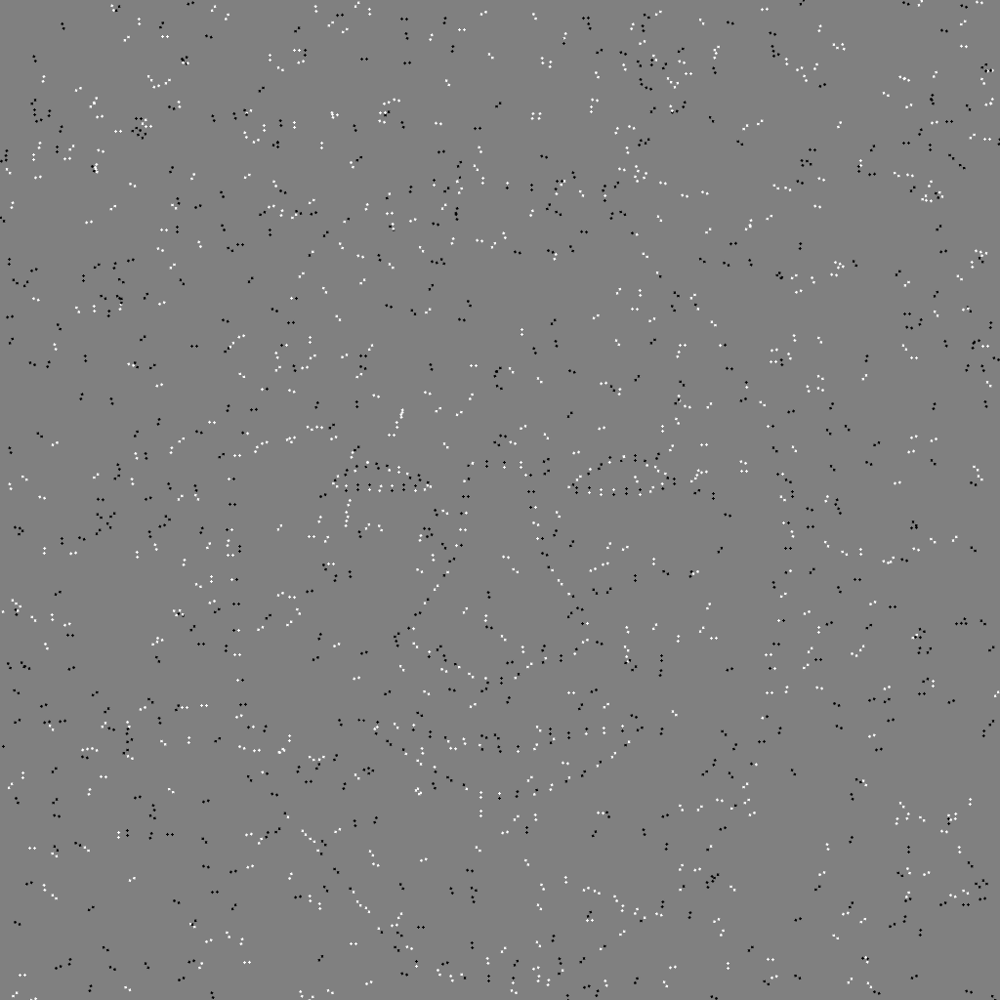

In [211]:
stimuli_pipeline(
    1170, 
    num_random_stimuli=1000, 
    exclusion_margin_pixels=10,
    circle_radius=0.25, 
    gap=0.75, 
    seed=42,
    use_original_background=False,
    contour_color_mode='fliptilt',
    smoothing_factor=10.0,
    show_intermediate_plots=False
)

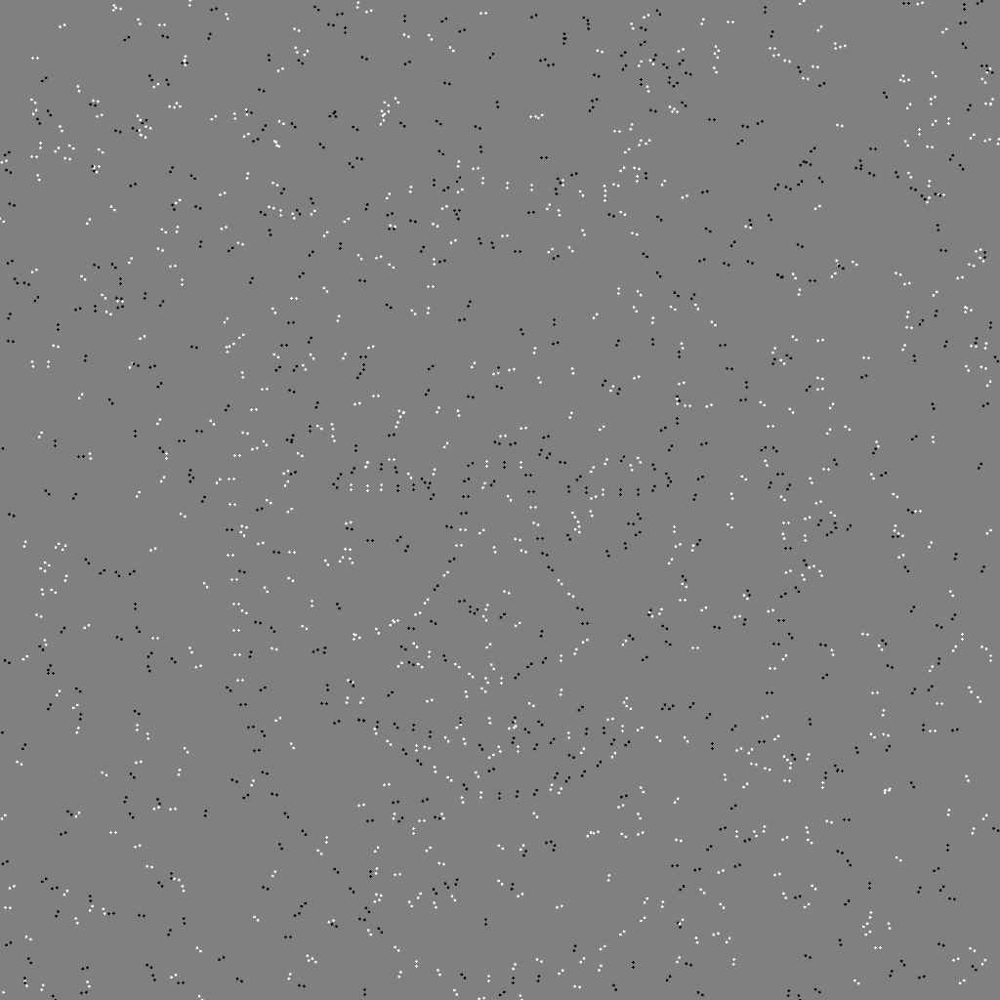

In [205]:
stimuli_pipeline(
    1170, 
    num_random_stimuli=1000, 
    exclusion_margin_pixels=10,
    circle_radius=0.25, 
    gap=0.75, 
    seed=42,
    use_original_background=False,
    contour_color_mode='random',
    smoothing_factor=10.0,
    show_intermediate_plots=False
)